# B01 怎样从天气 CSV 找到最热的一天？

输入是一份 10 天的教学天气记录。先不用 pandas：亲手把文本转成数字，遍历记录，输出日最高温、平均值和高温天数。

先修：能读懂变量赋值即可；本例讲解列表、字典、循环、函数和文件路径。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 读入：文件中的数字最初也是字符串
`with` 负责关闭文件，`DictReader` 用首行作字段名；`list` 把逐行读取器变成可重复查看的列表。输入是 CSV，输出是字典列表。先观察类型，避免按字符串大小排序。

In [2]:
import csv, json
with (DATA_DIR / 'weather.csv').open(encoding='utf-8', newline='') as stream:
    raw_rows = list(csv.DictReader(stream))
print(raw_rows[:2], type(raw_rows[0]['temp_max']))
assert len(raw_rows) == 10


[{'date': '2024-07-01', 'temp_max': '25'}, {'date': '2024-07-02', 'temp_max': '27'}] <class 'str'>


## 2. 转换：建立清楚的数据约定
逐条转成浮点数，同时检查日期和合理范围。`append` 将一条结果加入列表。检查失败时停止，比忽略错误继续出结论更容易排查。

In [3]:
from datetime import date
rows = []
for raw in raw_rows:
    value = float(raw['temp_max'])
    date.fromisoformat(raw['date'])
    assert -60 <= value <= 60
    rows.append({'date': raw['date'], 'temp_max': value})
print(rows[0])


{'date': '2024-07-01', 'temp_max': 25.0}


## 3. 函数：把统计过程变成能重复调用的步骤
函数接收记录与阈值，返回字典。最热日相同温度时保留最先出现的日期；空列表必须显式报错。循环里的累计和与计数，是以后向量化计算的基础。

In [4]:
def summarize(records, threshold=30):
    if not records:
        raise ValueError('没有记录，不能计算平均值')
    hottest = records[0]
    total = 0.0
    count = 0
    for row in records:
        total += row['temp_max']
        if row['temp_max'] > hottest['temp_max']:
            hottest = row
        if row['temp_max'] >= threshold:
            count += 1
    return {'hottest_date': hottest['date'], 'hottest_temp': hottest['temp_max'],
            'mean_temp': total / len(records), 'hot_days': count, 'threshold': threshold}
metrics = summarize(rows)
assert metrics['hottest_date'] == '2024-07-06'
assert metrics['hot_days'] == 4
print(metrics)


{'hottest_date': '2024-07-06', 'hottest_temp': 34.0, 'mean_temp': 28.6, 'hot_days': 4, 'threshold': 30}


## 4. 交付：数值与图互相检查
把结果写为 JSON，便于程序再次读取；图用于发现异常，不代替精确数值。折线的每个点应对应一行输入，阈值线帮助核对计数。

In [5]:
(OUT_DIR / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
plt.plot([r['date'][5:] for r in rows], [r['temp_max'] for r in rows], marker='o')
plt.axhline(30, linestyle='--', color='orange', label='30°C')
plt.ylabel('最高温度 / °C'); plt.xlabel('日期'); plt.legend(); plt.tight_layout()
plt.savefig(OUT_DIR / 'temperature.png'); plt.close()


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

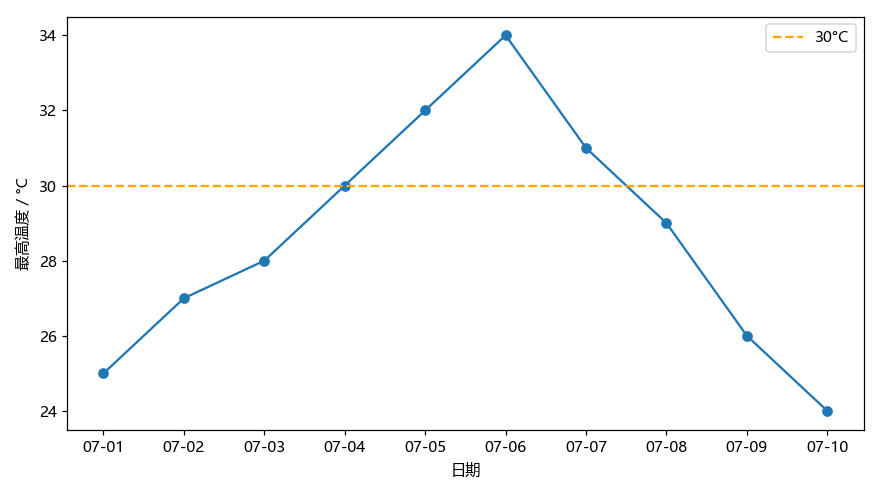

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
温度字符串必须转为数字；这里的均值是日最高温均值，不是全天平均温。小数据为手工构造，不能用于气候结论。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。